In [1]:
# ============================================================
# 1. ENVIRONMENT VERIFICATION
# ============================================================

import sys
import torch
import torchvision
import alibi

print("Python:", sys.version)
print("Environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Alibi:", alibi.__version__)
print("MPS available:", torch.backends.mps.is_available())

/Users/emanuelepasquini/.pyenv/versions/XAIalibi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.18 (main, Nov 23 2026, 18:11:22) [Clang 21.0.0 (clang-2100.1.1.101)]
Environment: /Users/emanuelepasquini/.pyenv/versions/XAIalibi/bin/python
PyTorch: 2.15.0
Torchvision: 0.29.2
Alibi: 0.9.6
MPS available: True


In [2]:

# ============================================================
# PROJECT PATH SETUP
# ============================================================

import sys
from pathlib import Path

# Add project root to Python path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)


Project root: /Users/emanuelepasquini/Library/CloudStorage/GoogleDrive-emanuele.pasquini@edu.unifi.it/Il mio Drive/università/MAGISTRALE/pw explainable/xai-counterfactuals


In [3]:

# ============================================================
# 2. LOAD PRETRAINED RESNET50
# ============================================================

from src.config import DEVICE, CHECKPOINT_DIR
from src.models import ResNet50Classifier

checkpoint_path = CHECKPOINT_DIR / "resnet50_exp10_scheduler_earlystop.pth"

model = ResNet50Classifier().to(DEVICE)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
)

model.eval()

print("Checkpoint:", checkpoint_path.name)
print("Device:", next(model.parameters()).device)
print("Evaluation mode:", not model.training)


Checkpoint: resnet50_exp10_scheduler_earlystop.pth
Device: mps:0
Evaluation mode: True


In [4]:

# ============================================================
# 3. PREDICTION FUNCTION FOR ALIBI - è una funzione che adatta l'input della resnet (i tensori e predice logits) e restituisce le probabilità predette per le due classi (Fake e Real)
# ============================================================

import numpy as np

def predict(images):
    """Return class probabilities for RGB images in [0, 1]."""

    # NumPy (N, H, W, C) -> PyTorch (N, C, H, W)
    images = np.asarray(images, dtype=np.float32)
    x = torch.from_numpy(images).permute(0, 3, 1, 2)

    # ImageNet normalization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    x = ((x - mean) / std).to(DEVICE)

    # Model predictions
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probabilities = torch.softmax(logits, dim=1)

    return probabilities.cpu().numpy()


In [5]:

# ============================================================
# 4. TEST PREDICTION FUNCTION
# ============================================================

from src.dataset import get_dataloaders

_, val_loader, _ = get_dataloaders()

# Load the first batch
images, labels = next(iter(val_loader))     # ti da un batch di immagini e labels dal validation loader, in particolare il primo batch (next(iter(val_loader))) di immagini e labels, che contiene 32 immagini e labels (perché il batch size è 32). Quindi images ha shape (32, 3, 224, 224)

# Undo ImageNet normalization for the first 2 images
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

images_np = (images[:2] * std + mean).clamp(0, 1)       # prime due immagini del batch, quindi images_np ha shape (2, 3, 224, 224)
images_np = images_np.permute(0, 2, 3, 1).numpy()

# Predict both images
probabilities = predict(images_np)

class_names = ["Fake", "Real"]

# per la label 0 e 1 del batch, cioè la prima immagine del batch, stampo la classe vera, le probabilità predette per le due classi e la classe predetta
for i in range(2):
    print(f"\nImage {i}")
    print("True class:", class_names[labels[i].item()])
    print("P(Fake):", round(float(probabilities[i, 0]), 4))
    print("P(Real):", round(float(probabilities[i, 1]), 4))
    print("Predicted class:", class_names[probabilities[i].argmax()])





Image 0
True class: Real
P(Fake): 0.8048
P(Real): 0.1952
Predicted class: Fake

Image 1
True class: Fake
P(Fake): 0.9994
P(Real): 0.0006
Predicted class: Fake


True class: Fake
Predicted class: Fake
Probabilities: [9.993992e-01 6.007923e-04]


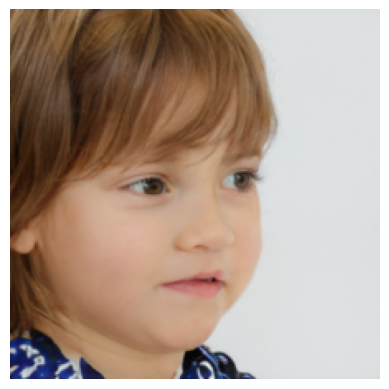

True class: Real
Predicted class: Real
Probabilities: [0.019811   0.98018897]


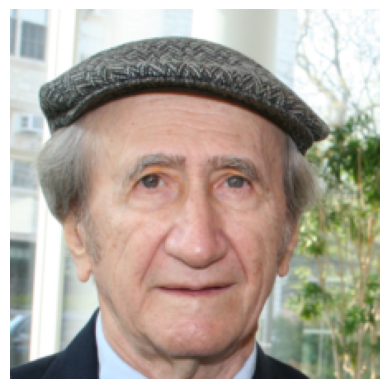

In [6]:

# Select a correctly classified validation image

import matplotlib.pyplot as plt

images_np = (images * std + mean).clamp(0, 1)
images_np = images_np.permute(0, 2, 3, 1).numpy()

probabilities = predict(images_np)
predictions = probabilities.argmax(axis=1)

correct_indices = np.where(predictions == labels.numpy())[0]

idx = correct_indices[0]

# Save image for counterfactual experiments
x_original = images_np[idx:idx+1]

print("True class:", ["Fake", "Real"][labels[idx].item()])
print("Predicted class:", ["Fake", "Real"][predictions[idx]])
print("Probabilities:", probabilities[idx])
plt.imshow(x_original[0])
plt.axis("off")
plt.show()

idx = correct_indices[1]
x_original = images_np[idx:idx+1]
print("True class:", ["Fake", "Real"][labels[idx].item()])
print("Predicted class:", ["Fake", "Real"][predictions[idx]])
print("Probabilities:", probabilities[idx])
plt.imshow(x_original[0])
plt.axis("off")
plt.show()


# ORA PROVIAMO IL PRIMO TEST DI ALIBI SU FFHQ SU RESNET50 - partendo da una dim piccola e poi ingrandendo con resnet50 - Counterfactual Instances (CF)

In [ ]:

# ============================================================
# 5. SELECT A FAKE IMAGE FOR COUNTERFACTUAL GENERATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

x_original = None

model.eval()

with torch.no_grad():
    for images, labels in val_loader:

        logits = model(images.to(DEVICE))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

        predictions = probabilities.argmax(axis=1)
        labels_np = labels.numpy()

        # Correctly classified Fake images with moderate confidence
        indices = np.where(
            (labels_np == 0) &
            (predictions == 0) &
            (probabilities[:, 0] >= 0.60) &
            (probabilities[:, 0] <= 0.90)
        )[0]

        if len(indices) > 0:
            idx = int(indices[0])
            image = (images[idx:idx+1] * std + mean).clamp(0, 1)
            x_original = image.permute(0, 2, 3, 1).numpy()

            break

if x_original is None:
    print("No suitable image found.")
else:
    print("P(Fake):", predict(x_original)[0, 0])
    print("P(Real):", predict(x_original)[0, 1])

    plt.imshow(x_original[0])   # prima immagine del batch, e anche l'unica
    plt.title("Original Fake image")
    plt.axis("off")
    plt.show()


RuntimeError: Expected all tensors to be on the same device, but found at least two devices, mps:0 and cpu!

In [22]:

# ============================================================
# 6. LOW-DIMENSIONAL PERTURBATIONS
# ============================================================

import torch.nn.functional as F

GRID_SIZE = 16           # granularità dei dettagli della perturbazione, più è grande più dettagliata è la perturbazione, ma più è difficile da ottimizzare. In generale si può provare con valori come 4, 8, 16, ecc.

def apply_perturbation(z):
    """Apply a low-dimensional RGB perturbation to the original image."""

    z = np.asarray(z, dtype=np.float32)

    # (N, 4, 4, 3) -> (N, 3, 4, 4)
    z_tensor = torch.from_numpy(z).permute(0, 3, 1, 2)

    # Upsample the perturbation to the original image size
    delta = F.interpolate(
        z_tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # (N, 3, 224, 224) -> (N, 224, 224, 3)
    delta = delta.permute(0, 2, 3, 1).numpy()

    # Add perturbation to the original image
    x_modified = np.clip(x_original + delta, 0, 1)

    return x_modified.astype(np.float32)


def predict_lowdim(z):
    """Predict ResNet50 probabilities from low-dimensional perturbations."""

    images = apply_perturbation(z)
    return predict(images)


In [23]:

# ============================================================
# 7. TEST LOW-DIMENSIONAL PREDICTOR
# ============================================================

z_original = np.zeros((1, GRID_SIZE, GRID_SIZE, 3), dtype=np.float32)       # granularità dei dettagli della perturbazione, più è grande più dettagliata è la perturbazione, ma più è difficile da ottimizzare. In generale si può provare con valori come 4, 8, 16, ecc.

p_original = predict(x_original)
p_lowdim = predict_lowdim(z_original)

print("Original probabilities:", p_original[0])
print("Low-dimensional probabilities:", p_lowdim[0])

print("Maximum image difference:",
      np.max(np.abs(
          x_original - apply_perturbation(z_original)
      )))

print("Predictions match:",
      np.allclose(p_original, p_lowdim))


Original probabilities: [0.7810525  0.21894756]
Low-dimensional probabilities: [0.7810525  0.21894756]
Maximum image difference: 0.0
Predictions match: True


In [24]:

# ============================================================
# 8. BATCHED PREDICTION FOR ALIBI
# ============================================================

def predict_lowdim_batched(z, batch_size=8):
    z = np.asarray(z, dtype=np.float32)

    results = []

    for i in range(0, len(z), batch_size):
        z_batch = z[i:i + batch_size]

        images_batch = apply_perturbation(z_batch)
        probs = predict(images_batch)

        results.append(probs)

    return np.concatenate(results, axis=0)


# Check the predictor
z_original = np.zeros((1, GRID_SIZE, GRID_SIZE, 3), dtype=np.float32)       # granularità dei dettagli della perturbazione, più è grande più dettagliata è la perturbazione, ma più è difficile da ottimizzare. In generale si può provare con valori come 4, 8, 16, ecc.

print("Original:", predict(x_original)[0])
print("Low-dimensional:", predict_lowdim_batched(z_original)[0])


Original: [0.7810525  0.21894756]
Low-dimensional: [0.7810525  0.21894756]


In [25]:

# ============================================================
# 9. FIRST ALIBI COUNTERFACTUAL ON FFHQ
# ============================================================

import tensorflow as tf
from alibi.explainers import Counterfactual

if tf.executing_eagerly():
    tf.compat.v1.disable_eager_execution()

# Reset the default graph to avoid issues with TensorFlow sessions when running multiple times in a notebook
tf.compat.v1.reset_default_graph()

cf_faces = Counterfactual(
    predict_fn=predict_lowdim_batched,
    shape=(1, GRID_SIZE, GRID_SIZE, 3),     # granularità dei dettagli della perturbazione, più è grande più dettagliata è la perturbazione, ma più è difficile da ottimizzare. In generale si può provare con valori come 4, 8, 16, ecc.
    target_class="other",
    target_proba=0.7,
    tol=0.1,
    max_iter=40,
    max_lam_steps=1,
    lam_init=0.01,
    learning_rate_init=0.05,
    feature_range=(-0.25, 0.25),
    eps=0.01
)

explanation_faces = cf_faces.explain(z_original)

print("Counterfactual found:", explanation_faces.cf is not None)


Counterfactual found: True


ORIGINAL
P(Fake): 0.7811
P(Real): 0.2189

COUNTERFACTUAL
P(Fake): 0.3506
P(Real): 0.6494

Class changed: True


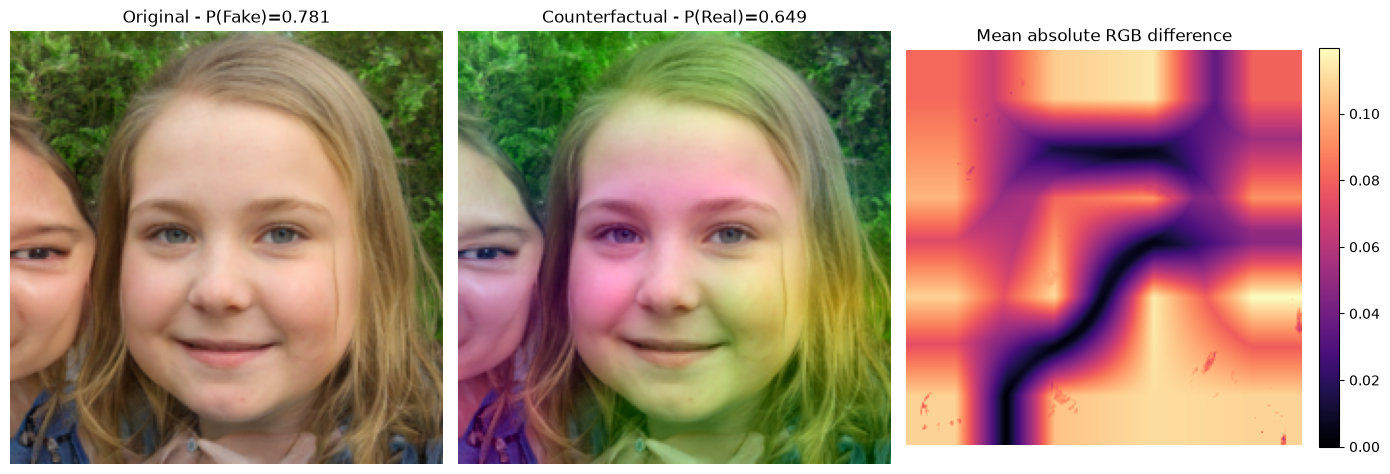

In [ ]:

# ============================================================
# 10. VISUALIZE THE COUNTERFACTUAL -- 4x4 GRID SIZE
# ============================================================

# Counterfactual perturbation found by Alibi (4, 4, 3)
z_cf = explanation_faces.cf["X"]

# Reconstruct the full-resolution image
x_cf = apply_perturbation(z_cf)

# Predictions before and after
p_original = predict(x_original)[0]
p_cf = predict(x_cf)[0]

print("ORIGINAL")
print(f"P(Fake): {p_original[0]:.4f}")
print(f"P(Real): {p_original[1]:.4f}")

print("\nCOUNTERFACTUAL")
print(f"P(Fake): {p_cf[0]:.4f}")
print(f"P(Real): {p_cf[1]:.4f}")

print("\nClass changed:", p_original.argmax() != p_cf.argmax())

# Difference between images
difference = np.abs(x_cf[0] - x_original[0])
difference_map = difference.mean(axis=2)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(x_original[0])
axes[0].set_title(f"Original - P(Fake)={p_original[0]:.3f}")

axes[1].imshow(x_cf[0])
axes[1].set_title(f"Counterfactual - P(Real)={p_cf[1]:.3f}")

im = axes[2].imshow(
    difference_map,
    cmap="magma",
    vmin=0,
    vmax=difference_map.max()
)
axes[2].set_title("Mean absolute RGB difference")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


ORIGINAL
P(Fake): 0.7811
P(Real): 0.2189

COUNTERFACTUAL
P(Fake): 0.3604
P(Real): 0.6396

Class changed: True


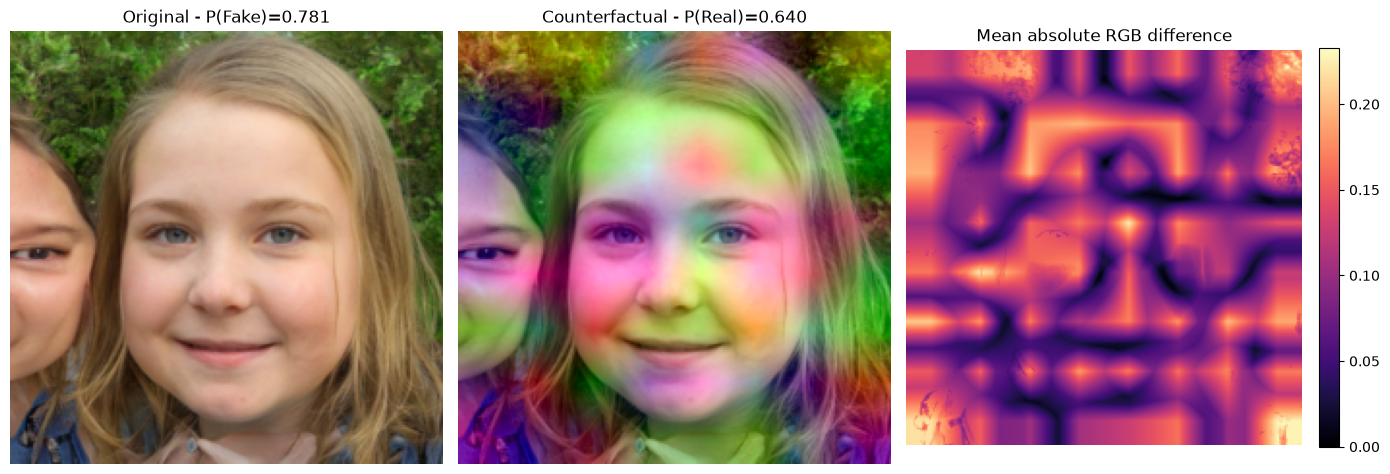

In [21]:

# ============================================================
# 10. VISUALIZE THE COUNTERFACTUAL -- 8x8 GRID SIZE
# ============================================================

# Counterfactual perturbation found by Alibi (4, 4, 3)
z_cf = explanation_faces.cf["X"]

# Reconstruct the full-resolution image
x_cf = apply_perturbation(z_cf)

# Predictions before and after
p_original = predict(x_original)[0]
p_cf = predict(x_cf)[0]

print("ORIGINAL")
print(f"P(Fake): {p_original[0]:.4f}")
print(f"P(Real): {p_original[1]:.4f}")

print("\nCOUNTERFACTUAL")
print(f"P(Fake): {p_cf[0]:.4f}")
print(f"P(Real): {p_cf[1]:.4f}")

print("\nClass changed:", p_original.argmax() != p_cf.argmax())

# Difference between images
difference = np.abs(x_cf[0] - x_original[0])
difference_map = difference.mean(axis=2)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(x_original[0])
axes[0].set_title(f"Original - P(Fake)={p_original[0]:.3f}")

axes[1].imshow(x_cf[0])
axes[1].set_title(f"Counterfactual - P(Real)={p_cf[1]:.3f}")

im = axes[2].imshow(
    difference_map,
    cmap="magma",
    vmin=0,
    vmax=difference_map.max()
)
axes[2].set_title("Mean absolute RGB difference")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


ORIGINAL
P(Fake): 0.7811
P(Real): 0.2189

COUNTERFACTUAL
P(Fake): 0.2721
P(Real): 0.7279

Class changed: True


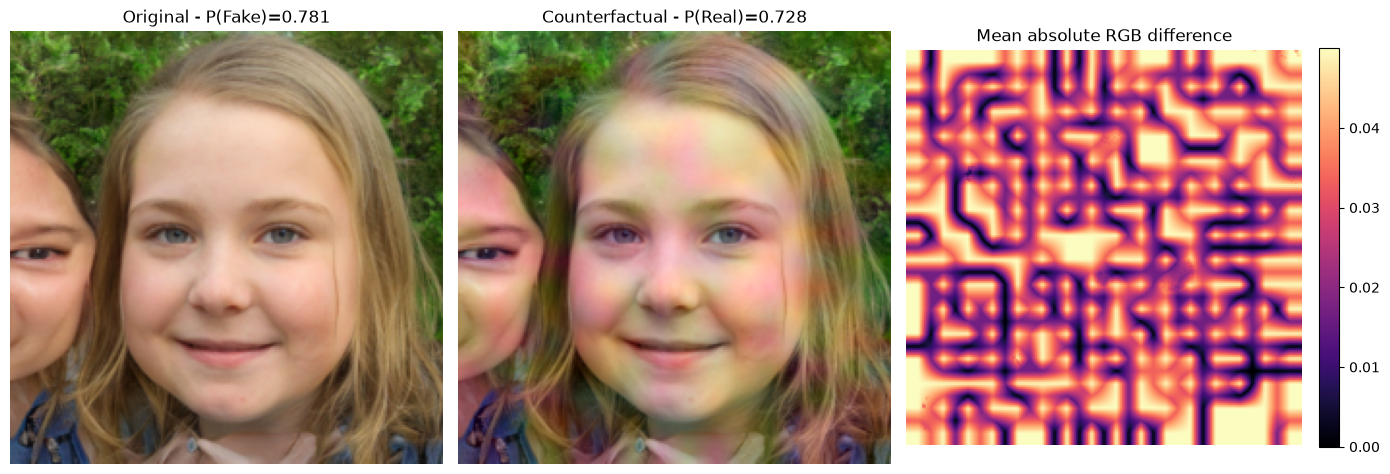

In [26]:

# ============================================================
# 10. VISUALIZE THE COUNTERFACTUAL -- 16x16 GRID SIZE
# ============================================================

# Counterfactual perturbation found by Alibi (4, 4, 3)
z_cf = explanation_faces.cf["X"]

# Reconstruct the full-resolution image
x_cf = apply_perturbation(z_cf)

# Predictions before and after
p_original = predict(x_original)[0]
p_cf = predict(x_cf)[0]

print("ORIGINAL")
print(f"P(Fake): {p_original[0]:.4f}")
print(f"P(Real): {p_original[1]:.4f}")

print("\nCOUNTERFACTUAL")
print(f"P(Fake): {p_cf[0]:.4f}")
print(f"P(Real): {p_cf[1]:.4f}")

print("\nClass changed:", p_original.argmax() != p_cf.argmax())

# Difference between images
difference = np.abs(x_cf[0] - x_original[0])
difference_map = difference.mean(axis=2)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(x_original[0])
axes[0].set_title(f"Original - P(Fake)={p_original[0]:.3f}")

axes[1].imshow(x_cf[0])
axes[1].set_title(f"Counterfactual - P(Real)={p_cf[1]:.3f}")

im = axes[2].imshow(
    difference_map,
    cmap="magma",
    vmin=0,
    vmax=difference_map.max()
)
axes[2].set_title("Mean absolute RGB difference")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [28]:

# ============================================================
# 11. COUNTERFACTUAL QUALITY METRICS
# ============================================================

delta = x_cf - x_original
abs_delta = np.abs(delta)

mae = np.mean(abs_delta)
rmse = np.sqrt(np.mean(delta ** 2))
max_change = np.max(abs_delta)

# Mean change across RGB channels for each pixel
pixel_change = np.mean(abs_delta, axis=-1)

print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"Maximum channel change: {max_change:.6f}")

print(
    "Pixels with mean RGB change > 0.05:",
    f"{100 * np.mean(pixel_change > 0.05):.2f}%"
)

print(
    "Change in P(Real):",
    f"{p_cf[1] - p_original[1]:+.4f}"
)

# Preserve this experiment for future comparisons
results_16 = {
    "grid_size": 16,
    "x_original": x_original.copy(),
    "x_cf": x_cf.copy(),
    "probabilities_original": p_original.copy(),
    "probabilities_cf": p_cf.copy(),
    "mae": float(mae),
    "rmse": float(rmse)
}


MAE: 0.030419
RMSE: 0.034690
Maximum channel change: 0.050000
Pixels with mean RGB change > 0.05: 0.00%
Change in P(Real): +0.5089


Aspetti positivi.  
- La perturbazione numericamente è piccola
- Nessun pixel ha avuto una variazione media > 0.05
- Eppure la probabilità di “Real” è aumentata di +0.5089, che è tanto
Questo vuol dire che il metodo è riuscito a trovare un cambiamento efficace con perturbazione moderata.

Aspetti problematici.  
Anche se la variazione numerica è piccola, visivamente il controfattuale appare ancora poco plausibile a livello umano, perché distribuisce piccole variazioni cromatiche un po’ ovunque.

In [29]:

# ============================================================
# 11. ACHROMATIC COUNTERFACTUAL - PREDICTION FUNCTIONS
# ============================================================

# Same spatial resolution as the previous RGB experiment
GRID_SIZE_GRAY = 16

def apply_perturbation_gray(z):
    """
    Apply an achromatic perturbation to the original RGB image.

    CHANGE 1: z has shape (N, 16, 16, 1), not (N, 16, 16, 3).
    CHANGE 2: the same perturbation is added to R, G and B.
    """

    z = np.asarray(z, dtype=np.float32)

    # (N, 16, 16, 1) -> (N, 1, 16, 16)
    z_tensor = torch.from_numpy(z).permute(0, 3, 1, 2)

    # Same bilinear interpolation as before
    delta = F.interpolate(
        z_tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # (N, 1, 224, 224) -> (N, 224, 224, 1)
    delta = delta.permute(0, 2, 3, 1).numpy()

    # CHANGE 3: NumPy broadcasts the single channel to RGB
    x_modified = np.clip(x_original + delta, 0, 1)

    return x_modified.astype(np.float32)


def predict_gray_batched(z, batch_size=8):
    """Same batched predictor, using achromatic perturbations."""

    z = np.asarray(z, dtype=np.float32)
    results = []

    for i in range(0, len(z), batch_size):
        z_batch = z[i:i + batch_size]

        # CHANGE 4: use the new achromatic transformation
        images_batch = apply_perturbation_gray(z_batch)
        results.append(predict(images_batch))

    return np.concatenate(results, axis=0)


# CHANGE 5: one channel instead of three
z_gray_original = np.zeros(
    (1, GRID_SIZE_GRAY, GRID_SIZE_GRAY, 1),
    dtype=np.float32
)

# Verify that zero perturbation leaves the image unchanged
assert np.allclose(
    x_original,
    apply_perturbation_gray(z_gray_original)
)

print("Input shape:", z_gray_original.shape)
print("Original probabilities:", predict(x_original)[0])
print("Gray predictor:", predict_gray_batched(z_gray_original)[0])


Input shape: (1, 16, 16, 1)
Original probabilities: [0.7810525  0.21894756]
Gray predictor: [0.7810525  0.21894756]


In [30]:

# ============================================================
# 12. ACHROMATIC COUNTERFACTUAL - ALIBI EXPERIMENT
# ============================================================

import time
import tensorflow as tf
from alibi.explainers import Counterfactual

# CHANGE 1: use a separate TensorFlow graph and session.
# This avoids conflicts with the previous RGB experiment.
tf_graph_gray = tf.Graph()
tf_session_gray = tf.compat.v1.Session(graph=tf_graph_gray)

start_time = time.perf_counter()

with tf_graph_gray.as_default(), tf_session_gray.as_default():

    cf_gray = Counterfactual(
        # CHANGE 2: new predictor using achromatic perturbations
        predict_fn=predict_gray_batched,

        # CHANGE 3: shape (1, 16, 16, 1) instead of (1, 16, 16, 3)
        shape=z_gray_original.shape,

        # All optimization parameters unchanged
        target_class="other",
        target_proba=0.7,
        tol=0.1,
        max_iter=40,
        max_lam_steps=1,
        lam_init=0.01,
        learning_rate_init=0.05,
        feature_range=(-0.25, 0.25),
        eps=0.01,

        # CHANGE 4: explicitly use the new TensorFlow session
        sess=tf_session_gray
    )

    explanation_gray = cf_gray.explain(z_gray_original)

elapsed_gray = time.perf_counter() - start_time

print(f"Execution time: {elapsed_gray / 60:.2f} minutes")
print("Counterfactual found:", explanation_gray.cf is not None)


# ============================================================
# EVALUATION AND VISUALIZATION
# ============================================================

if explanation_gray.cf is not None:

    # CHANGE 5: reconstruct using the new transformation
    z_cf_gray = explanation_gray.cf["X"]
    x_cf_gray = apply_perturbation_gray(z_cf_gray)

    p_original_gray = predict(x_original)[0]
    p_cf_gray = predict(x_cf_gray)[0]

    delta_gray = x_cf_gray - x_original
    difference_gray = np.abs(delta_gray).mean(axis=3)[0]

    mae_gray = np.mean(np.abs(delta_gray))
    rmse_gray = np.sqrt(np.mean(delta_gray ** 2))

    print("\nORIGINAL")
    print("P(Fake):", round(float(p_original_gray[0]), 4))
    print("P(Real):", round(float(p_original_gray[1]), 4))

    print("\nACHROMATIC COUNTERFACTUAL")
    print("P(Fake):", round(float(p_cf_gray[0]), 4))
    print("P(Real):", round(float(p_cf_gray[1]), 4))

    print("\nClass changed:",
          p_original_gray.argmax() != p_cf_gray.argmax())

    print(f"MAE: {mae_gray:.6f}")
    print(f"RMSE: {rmse_gray:.6f}")

    # Save experimental results
    results_gray = {
        "grid_size": GRID_SIZE_GRAY,
        "x_cf": x_cf_gray.copy(),
        "probabilities_cf": p_cf_gray.copy(),
        "mae": float(mae_gray),
        "rmse": float(rmse_gray),
        "time_seconds": elapsed_gray
    }

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))

    axes[0].imshow(x_original[0])
    axes[0].set_title(
        f"Original - P(Fake)={p_original_gray[0]:.3f}"
    )

    axes[1].imshow(x_cf_gray[0])
    axes[1].set_title(
        f"Achromatic CF - P(Real)={p_cf_gray[1]:.3f}"
    )

    im = axes[2].imshow(
        difference_gray,
        cmap="magma",
        vmin=0,
        vmax=max(float(difference_gray.max()), 1e-6)
    )
    axes[2].set_title("Mean absolute RGB difference")
    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No valid counterfactual found with these settings.")


No appropriate lambda range found, try decreasing lam_init


Execution time: 4.49 minutes
Counterfactual found: False
No valid counterfactual found with these settings.


Original             P(Real)=0.2189 | MAE=0.00000
RGB counterfactual   P(Real)=0.7279 | MAE=0.03042
Achromatic only      P(Real)=0.5946 | MAE=0.01066
Chromatic only       P(Real)=0.7496 | MAE=0.02726


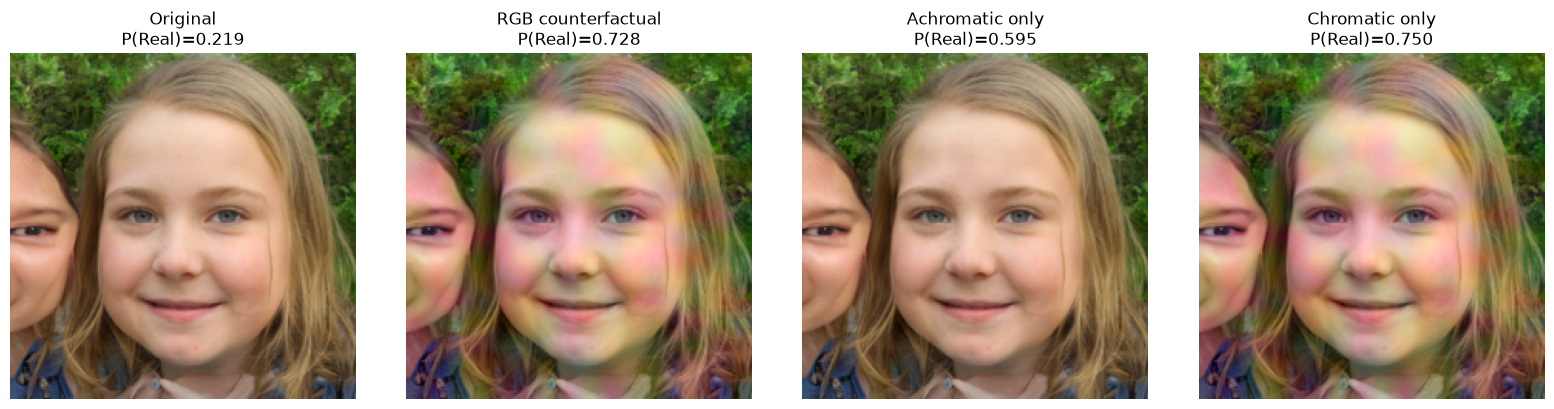

In [32]:

# ============================================================
# 14. ABLATION STUDY: ACHROMATIC VS CHROMATIC CHANGES
# ============================================================

# Original RGB counterfactual perturbation (16x16 experiment)
delta_rgb = x_cf - x_original

# Achromatic component: same change on R, G and B
delta_gray = delta_rgb.mean(axis=-1, keepdims=True)

# Chromatic component: differences between RGB channels
delta_chroma = delta_rgb - delta_gray

# Reconstruct images using each component separately
x_gray_only = np.clip(x_original + delta_gray, 0, 1)
x_chroma_only = np.clip(x_original + delta_chroma, 0, 1)

experiments = {
    "Original": x_original,
    "RGB counterfactual": x_cf,
    "Achromatic only": x_gray_only,
    "Chromatic only": x_chroma_only
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (name, image) in zip(axes, experiments.items()):
    probs = predict(image)[0]
    mae = np.mean(np.abs(image - x_original))

    print(f"{name:20s} P(Real)={probs[1]:.4f} | MAE={mae:.5f}")

    ax.imshow(image[0])
    ax.set_title(f"{name}\nP(Real)={probs[1]:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Ablation Study — Chromatic vs Achromatic Perturbations

**Obiettivo.** Nei precedenti esperimenti con Alibi `Counterfactual`, abbiamo osservato che ResNet50 può cambiare classificazione da *Fake* a *Real* in seguito a perturbazioni RGB, spesso accompagnate da artefatti cromatici poco realistici.

Abbiamo quindi cercato di capire **se il cambio di classificazione dipenda principalmente dalle variazioni cromatiche o possa essere ottenuto anche attraverso modifiche locali di luminosità**.

Un primo test con variazioni *uniformi* di luminosità non aveva prodotto alcun cambio di classe: la massima probabilità Real raggiunta era soltanto 0.2476. Inoltre, il tentativo di ottimizzare direttamente una perturbazione acromatica con Alibi non aveva trovato un controfattuale valido con i parametri utilizzati.

Per approfondire, abbiamo effettuato un **ablation study** sul controfattuale RGB già ottenuto con granularità \(16\times16\), decomponendo la perturbazione in:

- **Achromatic component:** variazione media dei tre canali RGB, applicata identicamente a ciascun canale.
- **Chromatic component:** variazioni residue dei singoli canali rispetto alla componente acromatica.

Le due componenti sono state applicate separatamente all'immagine originale, senza eseguire una nuova ottimizzazione.

#### Risultati

| Image | P(Real) | MAE | Prediction |
|---|---:|---:|---|
| Original | 0.2189 | 0.00000 | Fake |
| RGB Counterfactual | 0.7279 | 0.03042 | Real |
| Achromatic only | 0.5946 | 0.01066 | Real |
| Chromatic only | 0.7496 | 0.02726 | Real |

**Osservazioni principali.**

La componente **acromatica locale è sufficiente a invertire la classificazione**, pur producendo un'immagine visivamente molto simile all'originale e con un MAE inferiore rispetto al controfattuale RGB completo.

Anche la sola componente cromatica determina un cambio di classe, raggiungendo una probabilità Real superiore a quella del controfattuale completo. Questo evidenzia che la risposta della rete alle perturbazioni non è necessariamente additiva o monotona.

Il precedente fallimento dell'ottimizzazione acromatica con Alibi, quindi, **non implica l'assenza di controfattuali acromatici**: ne abbiamo identificato uno attraverso la decomposizione di una soluzione RGB.

#### Conclusione

Per questa specifica immagine, ResNet50 risulta sensibile sia alle modifiche cromatiche sia alle variazioni locali acromatiche. In particolare, la componente acromatica permette di cambiare classe con una perturbazione media ridotta e una migliore plausibilità visiva.

Tuttavia, questi risultati riguardano una sola immagine e perturbazioni ottenute da un controfattuale già ottimizzato: **non dimostrano che il modello utilizzi principalmente il colore o la luminosità per distinguere immagini Real e Fake**.

Il prossimo obiettivo è verificare se possiamo ridurre ulteriormente l'intensità della perturbazione acromatica mantenendo il cambio di classificazione.

Minimum alpha (grid): 0.225
P(Real): 0.5129
MAE: 0.002399


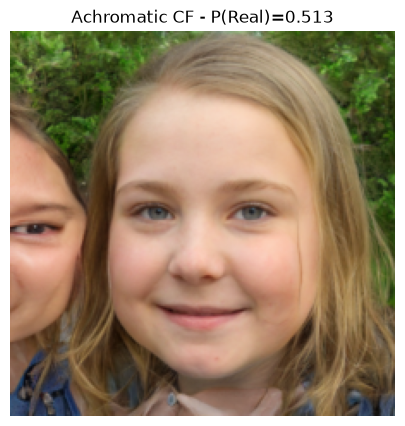

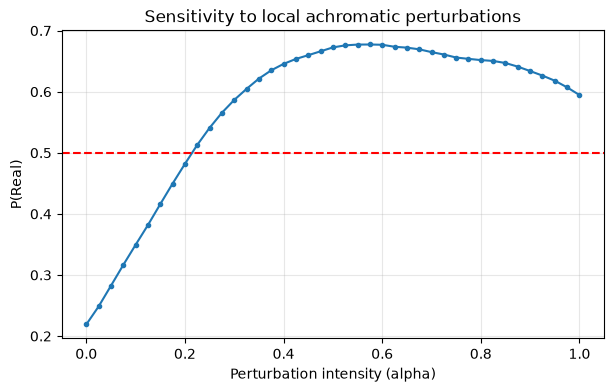

In [33]:

# ============================================================
# 15. MINIMUM ACHROMATIC PERTURBATION
# ============================================================

alphas = np.linspace(0, 1, 41)
delta_gray = (x_cf - x_original).mean(axis=-1, keepdims=True)

# Evaluate candidates in small batches
all_probs = []

for start in range(0, len(alphas), 8):
    alpha_batch = alphas[start:start + 8].reshape(-1, 1, 1, 1)

    candidates = np.clip(
        x_original + alpha_batch * delta_gray, 0, 1
    ).astype(np.float32)

    all_probs.append(predict(candidates))

all_probs = np.concatenate(all_probs, axis=0)
p_real = all_probs[:, 1]

# First alpha producing a Real prediction
valid_indices = np.where(p_real > 0.5)[0]

if len(valid_indices) > 0:
    idx = valid_indices[0]
    best_alpha = alphas[idx]

    x_gray_min = np.clip(
        x_original + best_alpha * delta_gray, 0, 1
    ).astype(np.float32)

    print(f"Minimum alpha (grid): {best_alpha:.3f}")
    print(f"P(Real): {p_real[idx]:.4f}")
    print(f"MAE: {np.mean(np.abs(x_gray_min - x_original)):.6f}")

    plt.figure(figsize=(5, 5))
    plt.imshow(x_gray_min[0])
    plt.title(f"Achromatic CF - P(Real)={p_real[idx]:.3f}")
    plt.axis("off")
    plt.show()

else:
    print("No class change found in the tested interval.")

# Probability as a function of perturbation intensity
plt.figure(figsize=(7, 4))
plt.plot(alphas, p_real, marker=".")
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("Perturbation intensity (alpha)")
plt.ylabel("P(Real)")
plt.title("Sensitivity to local achromatic perturbations")
plt.grid(alpha=0.3)
plt.show()


In [35]:

# ============================================================
# SAVE FIRST SUCCESSFUL FFHQ COUNTERFACTUAL
# ============================================================

from pathlib import Path
from PIL import Image
import json

output_dir = PROJECT_ROOT / "results" / "counterfactuals"
output_dir.mkdir(parents=True, exist_ok=True)

def save_rgb(image, path):
    image_uint8 = np.rint(
        np.clip(image[0], 0, 1) * 255
    ).astype(np.uint8)
    Image.fromarray(image_uint8).save(path)

save_rgb(x_original, output_dir / "ffhq_01_original.png")
save_rgb(x_gray_min, output_dir / "ffhq_01_cf_achromatic.png")

metrics = {
    "method": "Alibi CF + achromatic post-processing",
    "direction": "Fake to Real",
    "grid_size": 16,
    "alpha": float(best_alpha),
    "original_p_real": float(predict(x_original)[0, 1]),
    "counterfactual_p_real": float(predict(x_gray_min)[0, 1]),
    "mae": float(np.mean(np.abs(x_gray_min - x_original)))
}

with open(output_dir / "ffhq_01_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("First counterfactual saved:", output_dir)


First counterfactual saved: /Users/emanuelepasquini/Library/CloudStorage/GoogleDrive-emanuele.pasquini@edu.unifi.it/Il mio Drive/università/MAGISTRALE/pw explainable/xai-counterfactuals/results/counterfactuals


# SECONDO METODO CF GUIDED BY PROTOTYPE

In [36]:

# ============================================================
# 17. COUNTERFACTUAL PROTOTYPES - REFERENCE IMAGES
# ============================================================

from PIL import Image
from src.dataset import get_dataloaders, get_transforms

# Reference images must come from the TRAINING set
train_loader, _, _ = get_dataloaders()

train_subset = train_loader.dataset
image_folder = train_subset.dataset

# Select 20 images per class
N_PER_CLASS = 20
ref_paths = {0: [], 1: []}

for idx in train_subset.indices:
    path, label = image_folder.samples[idx]

    if len(ref_paths[label]) < N_PER_CLASS:
        ref_paths[label].append(path)

    if all(len(paths) == N_PER_CLASS for paths in ref_paths.values()):
        break

# Use the evaluation transform (no augmentation)
eval_transform = get_transforms(training=False)

mean_rgb = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std_rgb = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

reference_images = []
reference_labels = []

for label, paths in ref_paths.items():
    for path in paths:
        with Image.open(path) as img:
            x = eval_transform(img.convert("RGB"))

        # Undo normalization: obtain RGB pixels in [0, 1]
        x = (x * std_rgb + mean_rgb).clamp(0, 1)

        reference_images.append(x.permute(1, 2, 0).numpy())
        reference_labels.append(label)

reference_images = np.stack(reference_images).astype(np.float32)
reference_labels = np.array(reference_labels)

# Keep only correctly classified reference images
reference_probs = np.concatenate([
    predict(reference_images[i:i+8])
    for i in range(0, len(reference_images), 8)
], axis=0)

correct = reference_probs.argmax(axis=1) == reference_labels

reference_images = reference_images[correct]
reference_labels = reference_labels[correct]

print("Reference shape:", reference_images.shape)
print("Fake references:", np.sum(reference_labels == 0))
print("Real references:", np.sum(reference_labels == 1))

assert np.any(reference_labels == 0)
assert np.any(reference_labels == 1)


Reference shape: (40, 224, 224, 3)
Fake references: 20
Real references: 20


Original P(Real): 0.21894756
Prototype P(Real): 0.9999887
First class change at alpha: 0.7000000000000001


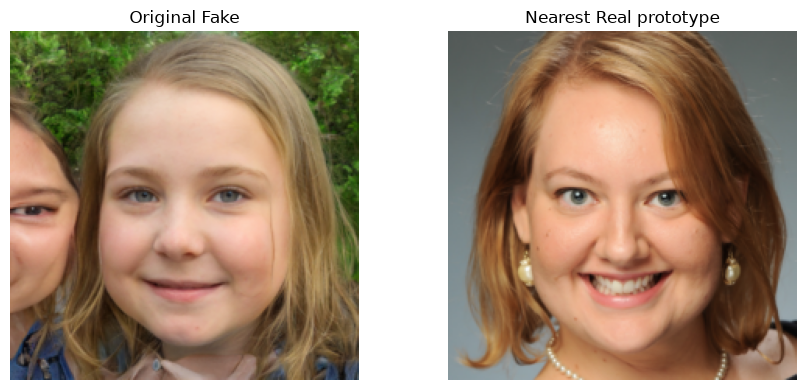

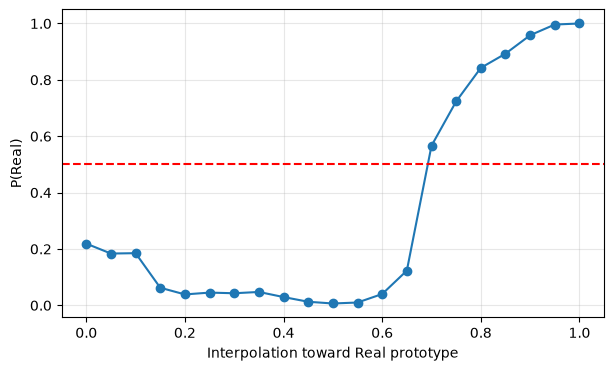

In [38]:

# ============================================================
# 19. CFPROTO - INSPECT TARGET PROTOTYPE
# ============================================================

# Prototype selected by CFProto for the target class Real (1)
x_proto = cf_proto.class_proto[1].reshape(
    1, 224, 224, 3
).astype(np.float32)

print("Original P(Real):", predict(x_original)[0, 1])
print("Prototype P(Real):", predict(x_proto)[0, 1])

# Interpolate from the original face to the Real prototype
alphas = np.linspace(0, 1, 21)

p_real = []

for alpha in alphas:
    x_interpolated = (
        (1 - alpha) * x_original + alpha * x_proto
    ).astype(np.float32)

    p_real.append(predict(x_interpolated)[0, 1])

p_real = np.array(p_real)

# Find first change in predicted class
valid = np.where(p_real > 0.5)[0]

if len(valid) > 0:
    alpha_flip = alphas[valid[0]]
    print("First class change at alpha:", alpha_flip)
else:
    print("No class change along the tested path.")

# Show the original and the Real prototype
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(x_original[0])
axes[0].set_title("Original Fake")

axes[1].imshow(x_proto[0])
axes[1].set_title("Nearest Real prototype")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Classification along the interpolation path
plt.figure(figsize=(7, 4))
plt.plot(alphas, p_real, marker="o")
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("Interpolation toward Real prototype")
plt.ylabel("P(Real)")
plt.grid(alpha=0.3)
plt.show()


In [37]:

# ============================================================
# 18. COUNTERFACTUAL PROTO - FIRST FFHQ EXPERIMENT
# ============================================================

import time
import tensorflow as tf
from alibi.explainers import CounterfactualProto

# Flatten the RGB images for KDTree compatibility
IMAGE_SHAPE = (224, 224, 3)

x_flat = x_original.reshape(1, -1)
references_flat = reference_images.reshape(len(reference_images), -1)

# Adapter: flat image -> ResNet50 prediction
def predict_flat(images_flat):
    images_rgb = images_flat.reshape((-1,) + IMAGE_SHAPE)
    return predict(images_rgb)

# New TensorFlow graph: no kernel restart needed
proto_graph = tf.Graph()

with proto_graph.as_default():
    proto_session = tf.compat.v1.Session(graph=proto_graph)

    with proto_session.as_default():

        cf_proto = CounterfactualProto(
            predict=predict_flat,
            shape=x_flat.shape,
            use_kdtree=True,
            theta=1.0,
            beta=0.1,
            feature_range=(0.0, 1.0),
            c_init=0.0,
            c_steps=1,
            max_iterations=200,
            learning_rate_init=0.01,
            sess=proto_session
        )

        # Build real/fake reference prototypes
        cf_proto.fit(references_flat)

        start = time.perf_counter()

        # Target class: Real = 1
        explanation_proto = cf_proto.explain(
            x_flat,
            target_class=[1],
            k=1,
            verbose=False
        )

        elapsed = time.perf_counter() - start

print(f"Execution time: {elapsed:.1f} seconds")
print("Counterfactual found:", explanation_proto.cf is not None)

if explanation_proto.cf is not None:
    x_cf_proto = explanation_proto.cf["X"].reshape(
        (1,) + IMAGE_SHAPE
    )

    p_proto = predict(x_cf_proto)[0]

    print("P(Fake):", round(float(p_proto[0]), 4))
    print("P(Real):", round(float(p_proto[1]), 4))
    print("MAE:", np.mean(np.abs(x_cf_proto - x_original)))

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    axes[0].imshow(x_original[0])
    axes[0].set_title("Original - Fake")

    axes[1].imshow(x_cf_proto[0])
    axes[1].set_title(f"CFProto - P(Real)={p_proto[1]:.3f}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


No encoder specified. Using k-d trees to represent class prototypes.
No counterfactual found!


Execution time: 2.3 seconds
Counterfactual found: False


# lasciamo stare per un attimo questo e proviamo quello che ci interessa veramente - CFRL

In [39]:

# ============================================================
# 20. COUNTERFACTUAL RL - PYTORCH SETUP
# ============================================================

import torch
import alibi

from alibi.explainers import CounterfactualRL
from alibi.models.pytorch import Actor, Critic

print("Alibi version:", alibi.__version__)
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

print("CFRL:", CounterfactualRL)
print("Actor:", Actor)
print("Critic:", Critic)

# The existing ResNet50 is still our black-box classifier
print("Original prediction:", predict(x_original)[0])


Alibi version: 0.9.6
PyTorch version: 2.15.0
MPS available: True
CFRL: <class 'alibi.explainers.cfrl_base.CounterfactualRL'>
Actor: <class 'alibi.models.pytorch.actor_critic.Actor'>
Critic: <class 'alibi.models.pytorch.actor_critic.Critic'>
Original prediction: [0.7810525  0.21894756]


In [40]:

# ============================================================
# 21. CFRL - FACE AUTOENCODER
# ============================================================

import torch
import torch.nn as nn

LATENT_DIM = 128
AE_DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)


class FaceEncoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 128, 4, stride=2, padding=1),
            nn.ReLU()
        )

        self.fc = nn.Linear(128 * 7 * 7, latent_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.flatten(start_dim=1)
        return torch.tanh(self.fc(x))


class FaceDecoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 128 * 7 * 7)

        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 128, 7, 7)
        return self.deconv(x)


encoder = FaceEncoder(LATENT_DIM).to(AE_DEVICE)
decoder = FaceDecoder(LATENT_DIM).to(AE_DEVICE)

print("Autoencoder device:", AE_DEVICE)


Autoencoder device: mps


In [41]:

# ============================================================
# 22. CFRL - AUTOENCODER SHAPE TEST
# ============================================================

# x_original is an RGB image in [0, 1], shape (1, 224, 224, 3)
x_test = torch.from_numpy(x_original).float()
x_test = x_test.permute(0, 3, 1, 2).to(AE_DEVICE)

encoder.eval()
decoder.eval()

with torch.no_grad():
    z_test = encoder(x_test)
    x_reconstructed = decoder(z_test)

print("Original:", tuple(x_test.shape))
print("Latent:", tuple(z_test.shape))
print("Reconstructed:", tuple(x_reconstructed.shape))

assert x_test.shape == x_reconstructed.shape
assert z_test.shape == (1, LATENT_DIM)

print("Shape test passed!")


Original: (1, 3, 224, 224)
Latent: (1, 128)
Reconstructed: (1, 3, 224, 224)
Shape test passed!


In [42]:

# ============================================================
# 23. CFRL - TRAIN FACE AUTOENCODER
# ============================================================

import torch.optim as optim
from pathlib import Path

# Training configuration
AE_EPOCHS = 5
AE_LR = 1e-3

# Undo ImageNet normalization
ae_mean = torch.tensor(
    [0.485, 0.456, 0.406],
    device=AE_DEVICE
).view(1, 3, 1, 1)

ae_std = torch.tensor(
    [0.229, 0.224, 0.225],
    device=AE_DEVICE
).view(1, 3, 1, 1)

def prepare_ae_images(images):
    images = images.to(AE_DEVICE)
    return (images * ae_std + ae_mean).clamp(0, 1)


# Optimizer and reconstruction loss
optimizer_ae = optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()),
    lr=AE_LR
)

criterion_ae = nn.MSELoss()

train_losses = []
val_losses = []
best_val_loss = float("inf")

checkpoint_ae = CHECKPOINT_DIR / "face_autoencoder_cfrl.pth"

for epoch in range(AE_EPOCHS):

    # ---------------- TRAIN ----------------
    encoder.train()
    decoder.train()

    total_train_loss = 0.0
    train_samples = 0

    for images, _ in train_loader:

        x = prepare_ae_images(images)

        optimizer_ae.zero_grad()

        z = encoder(x)
        x_hat = decoder(z)

        loss = criterion_ae(x_hat, x)

        loss.backward()
        optimizer_ae.step()

        total_train_loss += loss.item() * x.size(0)
        train_samples += x.size(0)

    train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    encoder.eval()
    decoder.eval()

    total_val_loss = 0.0
    val_samples = 0

    with torch.no_grad():
        for images, _ in val_loader:

            x = prepare_ae_images(images)

            z = encoder(x)
            x_hat = decoder(z)

            loss = criterion_ae(x_hat, x)

            total_val_loss += loss.item() * x.size(0)
            val_samples += x.size(0)

    val_loss = total_val_loss / val_samples

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{AE_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    # Save best autoencoder
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "encoder": encoder.state_dict(),
            "decoder": decoder.state_dict(),
            "latent_dim": LATENT_DIM,
            "val_loss": val_loss,
            "epoch": epoch + 1
        }, checkpoint_ae)

        print("  Best checkpoint saved!")

print("\nTraining completed.")


Epoch 1/5 | Train Loss: 0.067027 | Val Loss: 0.064659
  Best checkpoint saved!
Epoch 2/5 | Train Loss: 0.065063 | Val Loss: 0.064578
  Best checkpoint saved!
Epoch 3/5 | Train Loss: 0.065148 | Val Loss: 0.064448
  Best checkpoint saved!
Epoch 4/5 | Train Loss: 0.064823 | Val Loss: 0.064457
Epoch 5/5 | Train Loss: 0.064834 | Val Loss: 0.064694

Training completed.


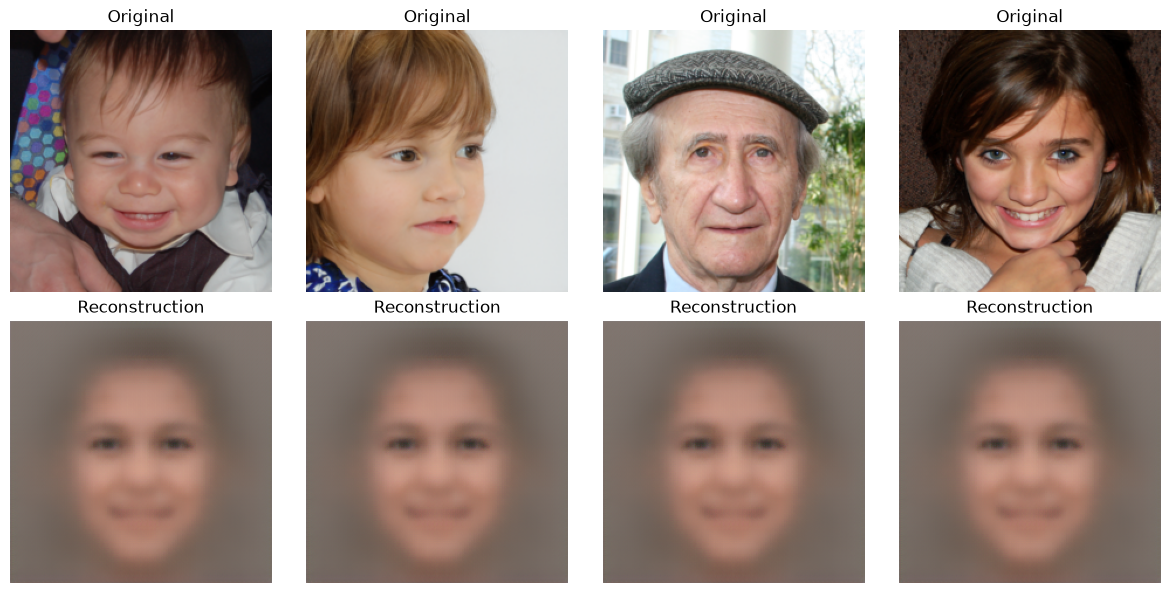

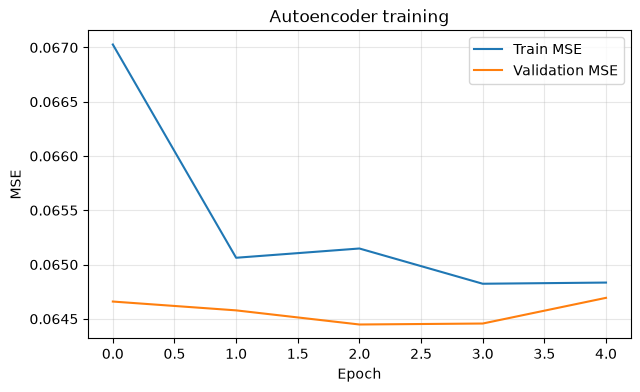

In [43]:

# ============================================================
# 24. CFRL - EVALUATE AUTOENCODER
# ============================================================

# Load best checkpoint
checkpoint = torch.load(
    checkpoint_ae,
    map_location=AE_DEVICE,
    weights_only=True
)

encoder.load_state_dict(checkpoint["encoder"])
decoder.load_state_dict(checkpoint["decoder"])

encoder.eval()
decoder.eval()

# Take 4 validation images
images, labels = next(iter(val_loader))
x = prepare_ae_images(images[:4])

with torch.no_grad():
    z = encoder(x)
    x_hat = decoder(z)

# Convert to NumPy for visualization
originals = x.permute(0, 2, 3, 1).cpu().numpy()
reconstructions = x_hat.permute(0, 2, 3, 1).cpu().numpy()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(originals[i])
    axes[0, i].set_title("Original")

    axes[1, i].imshow(reconstructions[i])
    axes[1, i].set_title("Reconstruction")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# Plot reconstruction losses
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train MSE")
plt.plot(val_losses, label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [45]:

# ============================================================
# 26. CHECK LATENT SATURATION
# ============================================================

encoder.eval()

with torch.no_grad():

    # Encoder before the final tanh
    h = encoder.conv(x)
    h = h.flatten(start_dim=1)

    pre_tanh = encoder.fc(h)
    z = torch.tanh(pre_tanh)

    print("Pre-tanh min:", pre_tanh.min().item())
    print("Pre-tanh max:", pre_tanh.max().item())

    print("Latent min:", z.min().item())
    print("Latent max:", z.max().item())

    print(
        "Percentage of saturated latent values:",
        100 * (z.abs() > 0.99).float().mean().item()
    )

    print(
        "Maximum difference between latent vectors:",
        (z[0] - z[1]).abs().max().item()
    )


Pre-tanh min: -15809.33203125
Pre-tanh max: 15846.66015625
Latent min: -1.0
Latent max: 1.0
Percentage of saturated latent values: 100.0
Maximum difference between latent vectors: 0.0


Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


Latent shape: torch.Size([1, 4, 28, 28])
Original: [0.7810525  0.21894756]
Reconstructed: [0.97350556 0.02649448]


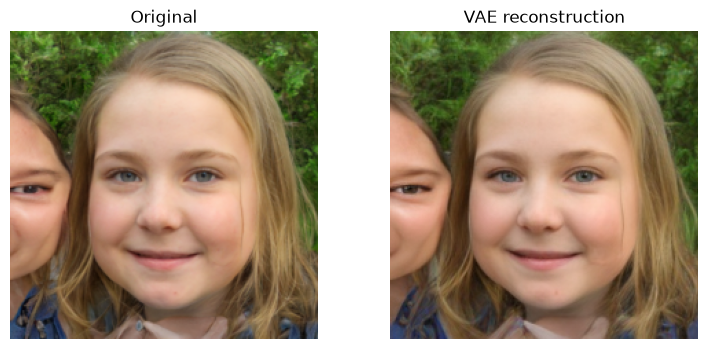

In [46]:

# ============================================================
# TEST PRETRAINED VAE - FFHQ RECONSTRUCTION - dopo aver installato il pacchetto diffusers
# ============================================================

from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained(
    "stabilityai/sd-vae-ft-mse"
).to("mps")

vae.eval()

# Original image: NumPy NHWC [0, 1] -> PyTorch NCHW [-1, 1]
x = torch.from_numpy(x_original).permute(0, 3, 1, 2).to("mps")
x = x * 2 - 1

with torch.no_grad():
    z = vae.encode(x).latent_dist.mode()
    x_hat = vae.decode(z).sample

# Convert back to NumPy [0, 1]
x_hat = ((x_hat + 1) / 2).clamp(0, 1)
x_hat = x_hat.permute(0, 2, 3, 1).cpu().numpy()

print("Latent shape:", z.shape)
print("Original:", predict(x_original)[0])
print("Reconstructed:", predict(x_hat)[0])

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(x_original[0])
ax[0].set_title("Original")
ax[1].imshow(x_hat[0])
ax[1].set_title("VAE reconstruction")

for a in ax:
    a.axis("off")
plt.show()


Class preservation: 70.0%
Mean MAE: 0.01993

Fake images:
Original accuracy: 95.0%
Reconstruction accuracy: 45.0%
Class preservation: 50.0%

Real images:
Original accuracy: 80.0%
Reconstruction accuracy: 90.0%
Class preservation: 90.0%


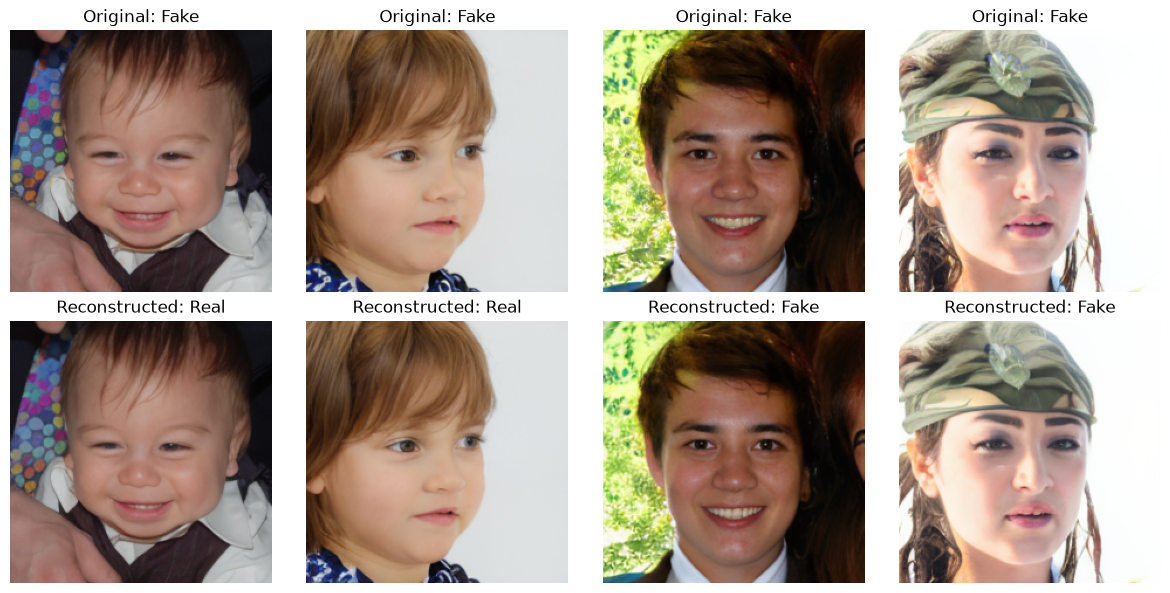

In [50]:

# ============================================================
# 28. PRETRAINED VAE - VALIDATION ON 40 FFHQ IMAGES
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

# Select 20 validation images per class
selected_images = []
selected_labels = []
counts = {0: 0, 1: 0}

mean_cpu = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std_cpu = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

for images, labels in val_loader:
    for i, label in enumerate(labels.tolist()):
        if counts[label] >= 20:
            continue

        rgb = (images[i:i+1] * std_cpu + mean_cpu).clamp(0, 1)
        selected_images.append(rgb[0].permute(1, 2, 0).numpy())
        selected_labels.append(label)
        counts[label] += 1

    if counts[0] == 20 and counts[1] == 20:
        break

X_val_vae = np.stack(selected_images).astype(np.float32)
Y_val_vae = np.array(selected_labels)

assert len(X_val_vae) == 40

# Reconstruct using the pretrained VAE
vae.eval()
vae_device = next(vae.parameters()).device
reconstructed_batches = []

with torch.inference_mode():
    for i in range(0, 40, 2):
        batch = torch.from_numpy(X_val_vae[i:i+2])
        batch = batch.permute(0, 3, 1, 2).to(vae_device)
        batch = batch * 2 - 1

        z = vae.encode(batch).latent_dist.mode()
        x_hat = vae.decode(z).sample

        x_hat = ((x_hat + 1) / 2).clamp(0, 1)
        reconstructed_batches.append(
            x_hat.permute(0, 2, 3, 1).cpu().numpy()
        )

X_reconstructed_vae = np.concatenate(reconstructed_batches)

# ResNet50 predictions
p_before = np.concatenate([
    predict(X_val_vae[i:i+8])
    for i in range(0, 40, 8)
])

p_after = np.concatenate([
    predict(X_reconstructed_vae[i:i+8])
    for i in range(0, 40, 8)
])

pred_before = p_before.argmax(axis=1)
pred_after = p_after.argmax(axis=1)

# Metrics
mae = np.abs(X_val_vae - X_reconstructed_vae).mean(axis=(1, 2, 3))

print("Class preservation:",
      f"{np.mean(pred_before == pred_after):.1%}")

print("Mean MAE:", round(float(mae.mean()), 5))

for cls, name in [(0, "Fake"), (1, "Real")]:
    mask = Y_val_vae == cls

    print(f"\n{name} images:")
    print("Original accuracy:",
          f"{np.mean(pred_before[mask] == Y_val_vae[mask]):.1%}")
    print("Reconstruction accuracy:",
          f"{np.mean(pred_after[mask] == Y_val_vae[mask]):.1%}")
    print("Class preservation:",
          f"{np.mean(pred_before[mask] == pred_after[mask]):.1%}")

# Visual comparison: 4 examples
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for j, i in enumerate([0, 1, 20, 21]):
    axes[0, j].imshow(X_val_vae[i])
    axes[0, j].set_title(
        f"Original: {['Fake', 'Real'][pred_before[i]]}"
    )

    axes[1, j].imshow(X_reconstructed_vae[i])
    axes[1, j].set_title(
        f"Reconstructed: {['Fake', 'Real'][pred_after[i]]}"
    )

    axes[0, j].axis("off")
    axes[1, j].axis("off")

plt.tight_layout()
plt.show()


Selected validation index: 6
True class: Fake
Original P(true): 0.9428
VAE P(true): 0.3792
Step 01/20 | P(true)=0.3792 | Loss=2.9285 | Time=168.8s
Target confidence reached!

========== RESULTS ==========
Total time: 424.9 seconds
Original P(true): 0.9428
VAE P(true): 0.3792
Optimized P(true): 0.9900
Final MAE: 0.014893
Class recovered: True


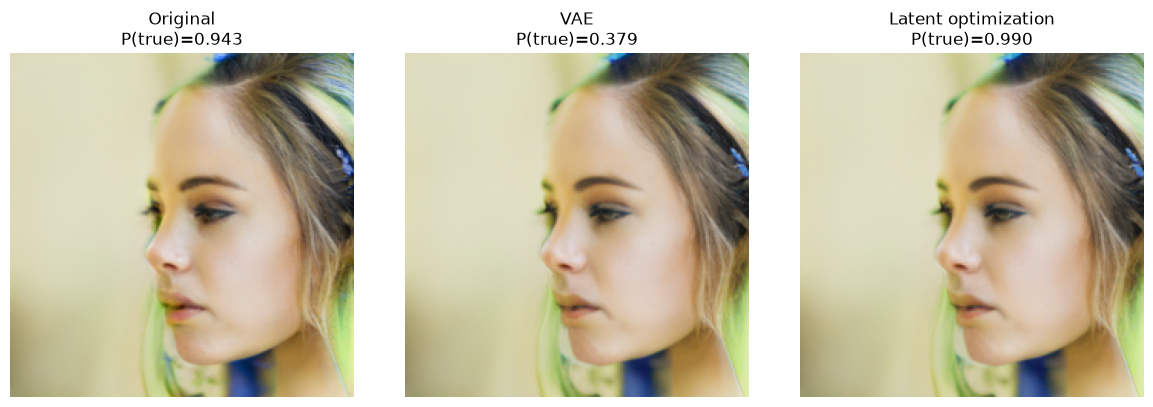

In [52]:

# ============================================================
# 29. FAST LATENT OPTIMIZATION - PRETRAINED VAE
# ============================================================

import time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

N_STEPS = 20                  # Previously: 150
LR_Z = 0.02
TARGET_CONFIDENCE = 0.90

LAMBDA_REC = 25.0
LAMBDA_CLS = 3.0
LAMBDA_LAT = 0.1

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Freeze both networks: optimize ONLY the latent vector
vae = vae.to(device).eval()
model = model.to(device).eval()

vae.requires_grad_(False)
model.requires_grad_(False)

mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)


# ------------------------------------------------------------
# 2. SELECT ONE IMAGE FROM PREVIOUS EXPERIMENT
# ------------------------------------------------------------

# CHANGE: reuse the 40 images already evaluated.
# No need to scan the dataset again.

pred_before = p_before.argmax(axis=1)
pred_after = p_after.argmax(axis=1)

candidates = np.where(
    (pred_before == Y_val_vae) &
    (pred_after != Y_val_vae)
)[0]

assert len(candidates) > 0, "No suitable images found."

# For this first test, choose the easiest case to recover
scores = p_after[candidates, Y_val_vae[candidates]]
idx = int(candidates[np.argmax(scores)])

x_orig = torch.from_numpy(
    X_val_vae[idx:idx+1]
).permute(0, 3, 1, 2).float().to(device)

y_true = torch.tensor(
    [int(Y_val_vae[idx])],
    dtype=torch.long,
    device=device
)

target_class = int(Y_val_vae[idx])

print("Selected validation index:", idx)
print("True class:", ["Fake", "Real"][target_class])
print("Original P(true):", round(float(p_before[idx, target_class]), 4))
print("VAE P(true):", round(float(p_after[idx, target_class]), 4))


# ------------------------------------------------------------
# 3. ENCODE THE IMAGE ONCE
# ------------------------------------------------------------

with torch.no_grad():
    z0 = vae.encode(x_orig * 2 - 1).latent_dist.mode()

# CHANGE: optimize one latent vector, not 12 simultaneously
z = z0.detach().clone().requires_grad_(True)

optimizer = torch.optim.Adam([z], lr=LR_Z)


def decode_latent(latent):
    # Raw VAE latents: no scaling factor is needed
    reconstruction = vae.decode(latent).sample
    return ((reconstruction + 1) / 2).clamp(0, 1)


# ------------------------------------------------------------
# 4. OPTIMIZATION
# ------------------------------------------------------------

start = time.perf_counter()

for step in range(1, N_STEPS + 1):

    optimizer.zero_grad(set_to_none=True)

    # Decode the modified latent
    x_fixed = decode_latent(z)

    # Differentiable ResNet50 prediction
    logits = model((x_fixed - mean) / std)

    # Reconstruction + classification + latent regularization
    loss_rec = F.mse_loss(x_fixed, x_orig)
    loss_cls = F.cross_entropy(logits, y_true)
    loss_lat = F.mse_loss(z, z0)

    loss = (
        LAMBDA_REC * loss_rec +
        LAMBDA_CLS * loss_cls +
        LAMBDA_LAT * loss_lat
    )

    # Prediction for monitoring (no extra forward pass)
    with torch.no_grad():
        p_true = torch.softmax(logits, dim=1)[0, target_class].item()

    if step == 1 or step % 5 == 0:
        elapsed = time.perf_counter() - start

        print(
            f"Step {step:02d}/{N_STEPS} | "
            f"P(true)={p_true:.4f} | "
            f"Loss={loss.item():.4f} | "
            f"Time={elapsed:.1f}s"
        )

    # CHANGE: stop when confidence is sufficiently high
    if p_true >= TARGET_CONFIDENCE:
        print("Target confidence reached!")
        break

    # Backpropagate through VAE + ResNet50,
    # updating ONLY z
    loss.backward()

    torch.nn.utils.clip_grad_norm_([z], max_norm=1.0)
    optimizer.step()


# ------------------------------------------------------------
# 5. FINAL EVALUATION
# ------------------------------------------------------------

with torch.no_grad():
    x_optimized = decode_latent(z)

    final_logits = model((x_optimized - mean) / std)
    final_probs = torch.softmax(final_logits, dim=1)[0]

    final_p_true = final_probs[target_class].item()
    final_mae = (x_optimized - x_orig).abs().mean().item()

total_time = time.perf_counter() - start

print("\n========== RESULTS ==========")
print(f"Total time: {total_time:.1f} seconds")
print(f"Original P(true): {p_before[idx, target_class]:.4f}")
print(f"VAE P(true): {p_after[idx, target_class]:.4f}")
print(f"Optimized P(true): {final_p_true:.4f}")
print(f"Final MAE: {final_mae:.6f}")
print("Class recovered:", final_p_true > 0.5)


# ------------------------------------------------------------
# 6. VISUALIZATION
# ------------------------------------------------------------

original = X_val_vae[idx]
reconstructed = X_reconstructed_vae[idx]

optimized = (
    x_optimized[0]
    .permute(1, 2, 0)
    .detach()
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original)
axes[0].set_title(
    f"Original\nP(true)={p_before[idx, target_class]:.3f}"
)

axes[1].imshow(reconstructed)
axes[1].set_title(
    f"VAE\nP(true)={p_after[idx, target_class]:.3f}"
)

axes[2].imshow(optimized)
axes[2].set_title(
    f"Latent optimization\nP(true)={final_p_true:.3f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [54]:

# ============================================================
# 31. LATENT OPTIMIZATION - SMALL BENCHMARK
# ============================================================

import time
import torch.nn.functional as F

N_TEST = 2
LR_Z = 0.02

# Select Fake images correctly classified before the VAE,
# but incorrectly classified after reconstruction
candidate_indices = np.where(
    (Y_val_vae == 0) &
    (p_before.argmax(axis=1) == 0) &
    (p_after.argmax(axis=1) == 1)
)[0]

selected = candidate_indices[:N_TEST]

device_vae = next(vae.parameters()).device

vae.eval().requires_grad_(False)
model = model.to(device_vae).eval().requires_grad_(False)

mean_b = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device_vae
).view(1, 3, 1, 1)

std_b = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device_vae
).view(1, 3, 1, 1)


def synchronize():
    # MPS runs operations asynchronously
    if device_vae.type == "mps":
        torch.mps.synchronize()


benchmark_results = []

for index in selected:

    x = torch.from_numpy(
        X_val_vae[index:index+1]
    ).permute(0, 3, 1, 2).to(device_vae)

    y = torch.tensor(
        [int(Y_val_vae[index])],
        device=device_vae
    )

    synchronize()
    start = time.perf_counter()

    # Encode once
    with torch.no_grad():
        z0 = vae.encode(x * 2 - 1).latent_dist.mode()

    # Optimize only the latent representation
    z = z0.detach().clone().requires_grad_(True)
    optimizer = torch.optim.Adam([z], lr=LR_Z)

    optimizer.zero_grad(set_to_none=True)

    x_hat = ((vae.decode(z).sample + 1) / 2).clamp(0, 1)
    logits = model((x_hat - mean_b) / std_b)

    loss = (
        25.0 * F.mse_loss(x_hat, x) +
        3.0 * F.cross_entropy(logits, y) +
        0.1 * F.mse_loss(z, z0)
    )

    # One optimization step
    loss.backward()
    optimizer.step()

    # Evaluate optimized image
    with torch.no_grad():
        x_fixed = ((vae.decode(z).sample + 1) / 2).clamp(0, 1)

        probs = torch.softmax(
            model((x_fixed - mean_b) / std_b),
            dim=1
        )[0]

        p_true = float(probs[y.item()].item())
        mae = float((x_fixed - x).abs().mean().item())

    synchronize()
    elapsed = time.perf_counter() - start

    benchmark_results.append({
        "index": int(index),
        "time_seconds": elapsed,
        "p_true_before": float(p_after[index, y.item()]),
        "p_true_after": p_true,
        "mae": mae
    })

    print(
        f"Image {index} | "
        f"Time: {elapsed:.1f}s | "
        f"P(true): {p_after[index, y.item()]:.3f} -> {p_true:.3f} | "
        f"MAE: {mae:.5f}"
    )

if benchmark_results:
    mean_time = np.mean([
        r["time_seconds"] for r in benchmark_results
    ])

    recovered = sum(
        r["p_true_after"] > 0.5 for r in benchmark_results
    )

    print("\n========== BENCHMARK ==========")
    print(f"Images tested: {len(benchmark_results)}")
    print(f"Average time per image: {mean_time:.1f}s")
    print(f"Classes recovered: {recovered}/{len(benchmark_results)}")


Image 1 | Time: 140.5s | P(true): 0.160 -> 0.993 | MAE: 0.01393
Image 5 | Time: 162.6s | P(true): 0.003 -> 0.631 | MAE: 0.01579

========== BENCHMARK ==========
Images tested: 2
Average time per image: 151.6s
Classes recovered: 2/2
